In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:

import numpy as np


class Cartella:
    def __init__(self, numeri):
        self.numeri = np.sort(np.asarray(numeri))

    def get_numbers(self):
        return self.numeri

    def self_sum(self):
        return np.sum(self.numeri)

    def common_numbers(self, other):
        """Numero di numeri condivisi tra due cartelle."""
        return len(np.intersect1d(self.numeri, other.numeri))

    def is_different(self, other, max_common=5):
        """
        Accetta la cartella se condivide al massimo
        max_common numeri con l'altra.
        """
        return self.common_numbers(other) <= max_common


def generate_tables(
    n_tables,
    n_available,
    n_per_table,
    max_common=5,
    max_attempts=1_000_000
):
    tables = []
    attempts = 0

    while len(tables) < n_tables and attempts < max_attempts:
        attempts += 1

        # Genera una cartella con numeri distinti
        numeri = np.random.choice(
            n_available,
            size=n_per_table,
            replace=False
        )

        tab = Cartella(numeri)

        # La nuova cartella deve essere diversa da tutte le precedenti
        if all(
            tab.is_different(other, max_common)
            for other in tables
        ):
            tables.append(tab)

    if len(tables) < n_tables:
        print(
            f"Attenzione: generate {len(tables)} cartelle "
            f"su {n_tables} richieste dopo {attempts} tentativi."
        )

    return tables


# Esempio: 1500 cartelle, 15 numeri ciascuna, 250 numeri disponibili
#tables = generate_tables(    n_tables=1500,n_available=100,n_per_table=15,max_common=5)

"""print("Cartelle generate:", len(tables))

# Esempio: visualizza le prime 5 cartelle
for i, tab in enumerate(tables[:5]):
    print(f"Cartella {i + 1}: {tab.get_numbers()}")
"""

'print("Cartelle generate:", len(tables))\n\n# Esempio: visualizza le prime 5 cartelle\nfor i, tab in enumerate(tables[:5]):\n    print(f"Cartella {i + 1}: {tab.get_numbers()}")\n'

In [4]:


def simulate_game(tables, n_available=100, rate=5):
    """
    Simula una partita.
    tables: lista di oggetti Cartella
    n_available: numeri disponibili
    rate: estrazioni al minuto

    Restituisce il tempo della prima tombola in minuti
    e il numero di giocatori che fanno tombola a quella estrazione.
    """

    estrazioni = np.random.permutation(
        np.arange(1, n_available + 1)
    )

    # Converte ogni cartella in un set per controlli rapidi
    cartelle = [set(tab.get_numbers()) for tab in tables]

    usciti = set()

    for k, numero in enumerate(estrazioni, start=1):
        usciti.add(numero)

        vincitori = sum(
            cartella.issubset(usciti)
            for cartella in cartelle
        )

        if vincitori > 0:
            tempo = k / rate
            return tempo, vincitori

    return n_available / rate, len(tables)



La funzione Python riceve i seguenti parametri:

- \(\texttt{rate}\): numero di estrazioni al minuto, indicato matematicamente con \(R\).
- \(\texttt{n\_giocatori}\): numero di giocatori, indicato con \(N\).
- \(\texttt{n\_per\_cartella}\): numero di elementi presenti in ogni cartella, indicato con \(n_c\).
- \(\texttt{n\_disponibili}\): numero totale di numeri estraibili, indicato con \(M\).
- \(\texttt{soglia}\): probabilità minima richiesta, indicata con \(\alpha\).

La riga

\[
\texttt{p = comb(k, $n_c$) / comb(M, $n_c$)}
\]

calcola la probabilità che una cartella sia completa dopo \(k\) estrazioni.

La riga

\[
\texttt{prob = binom.sf(1, N, p)}
\]

calcola la probabilità che almeno due giocatori abbiano completato la propria cartella.

Infine, il programma restituisce il numero di estrazioni, il tempo corrispondente in minuti e ore, la probabilità raggiunta e la probabilità individuale di completamento.


In [2]:

import numpy as np
from scipy.stats import binom
from math import comb


def tempo_due_tombole_95(
    rate,
    n_giocatori,
    n_per_cartella,
    n_disponibili=250,
    soglia=0.95
):
    """
    Calcola il tempo entro cui la probabilità di almeno
    due tombole raggiunge la soglia richiesta.

    Modello: cartelle indipendenti, generate uniformemente
    tra tutte le combinazioni possibili.
    Nessun Monte Carlo.
    """

    R = rate
    N = n_giocatori
    C = n_per_cartella
    M = n_disponibili

    if R <= 0 or N < 2 or C < 1 or C > M:
        raise ValueError("Parametri non validi.")

    for k in range(C, M + 1):

        # Probabilità che una cartella sia completa
        p = comb(k, C) / (comb(M, C)) #ho corretto il denominatore per dire che almeno le cinuquine devono essere tutte disgiunte

        # Probabilità che almeno due giocatori
        # abbiano fatto tombola
        prob = binom.sf(1, N, p)

        if prob >= soglia:
            tempo = k / R

            return {
                "estrazioni": k,
                "tempo_minuti": tempo,
                "tempo_ore": tempo / 60,
                "probabilita": prob,
                "probabilita_individuale": p
            }

    return {
        "estrazioni": M,
        "tempo_minuti": M / R,
        "tempo_ore": M / R / 60,
        "probabilita": 1.0,
        "probabilita_individuale": 1.0
    }


# Esempio
risultato = tempo_due_tombole_95(
    rate=4,                 # estrazioni al minuto
    n_giocatori=1500,
    n_per_cartella=15,
    n_disponibili=250,
    soglia=0.95
)

for chiave, valore in risultato.items():
    print(f"{chiave}: {valore}")


estrazioni: 173
tempo_minuti: 43.25
tempo_ore: 0.7208333333333333
probabilita: 0.9572126683192221
probabilita_individuale: 0.0032835934678509854


In [6]:
risultato = tempo_due_tombole_95(
    rate=4,                 # estrazioni al minuto
    n_giocatori=1500,
    n_per_cartella=15,
    n_disponibili=250,
    soglia=0.9
)

Text(0.5, 0, 'numero giocatori')

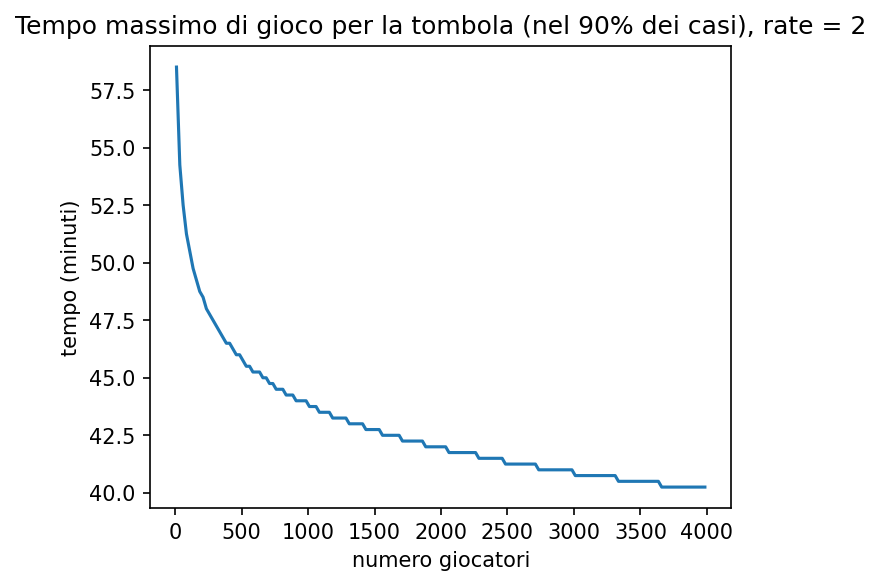

In [7]:
plt.figure(figsize=(5,4), dpi = 150)
n_giocatori = np.arange(10, 4000, 25)
tempo = [tempo_due_tombole_95( 4, n,15,n_disponibili=250, soglia = 0.9)["tempo_minuti"] for n in n_giocatori]

plt.plot(n_giocatori,tempo)
plt.title("Tempo massimo di gioco per la tombola (nel 90% dei casi), rate = 2")
plt.ylabel("tempo (minuti)")
plt.xlabel("numero giocatori")

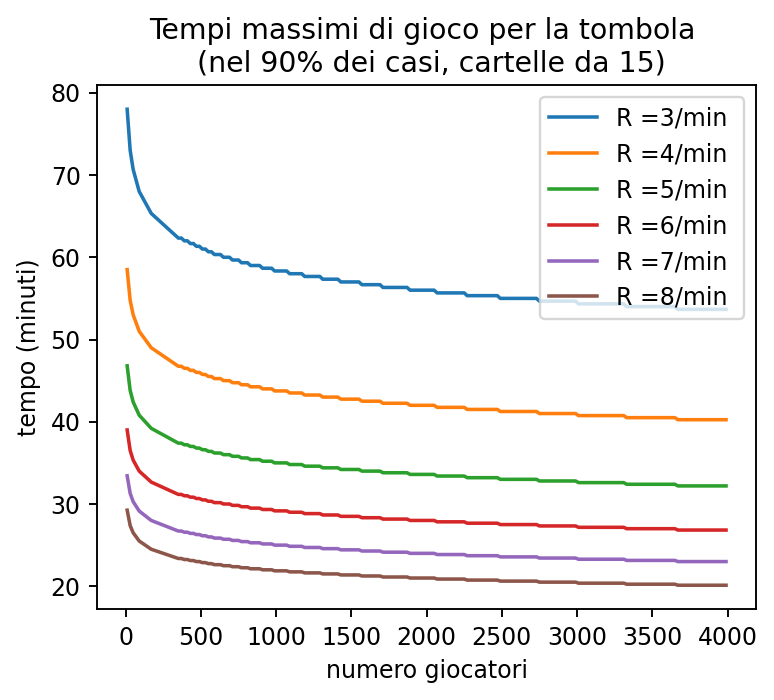

In [16]:
rates = np.linspace(3,8, 6)
n_giocatori = np.arange(10, 4000, 20)
plt.figure(figsize=(5,4), dpi = 170)
print
rate_dependent = {}
for r in rates:
    tempi = [tempo_due_tombole_95( r, n,15,n_disponibili=250, soglia = 0.9)["tempo_minuti"] for n in n_giocatori]

    rate_dependent[r] = tempi

    plt.plot(n_giocatori,tempi, label = f"R ={r:.0f}/min ")
plt.title("Tempi massimi di gioco per la tombola \n (nel 90% dei casi, cartelle da 15)")
plt.ylabel("tempo (minuti)")
plt.xlabel("numero giocatori")
plt.legend()
plt.savefig("rate_dependent.jpg")

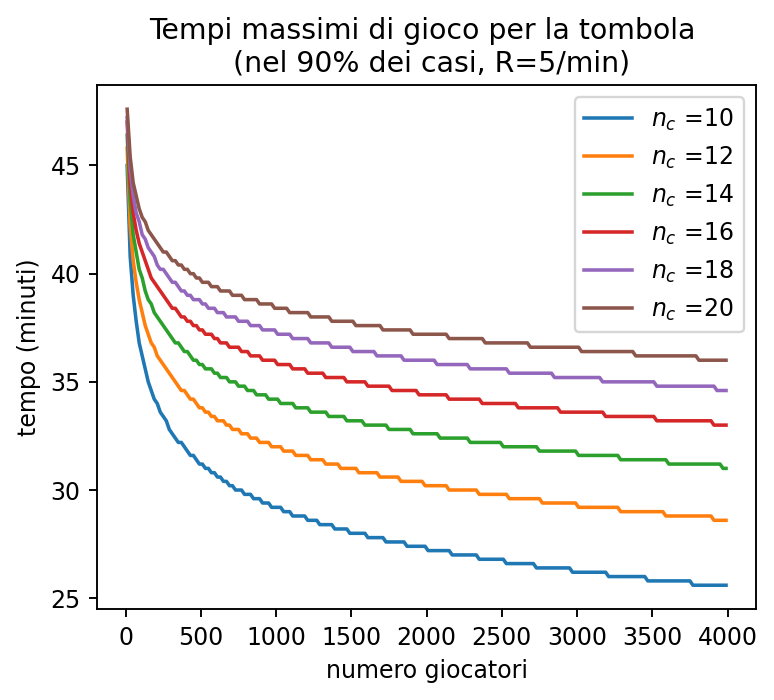

In [17]:
n_caselle = [l for l in range(10, 22,2)]
n_giocatori = np.arange(10, 4000, 20)
plt.figure(figsize=(5,4), dpi = 170)
print
n_dependent = {}
for n_c in n_caselle:
    tempi = [tempo_due_tombole_95( rate = 5, n_giocatori =n,n_per_cartella = n_c,n_disponibili=250, soglia = 0.9)["tempo_minuti"] for n in n_giocatori]

    n_dependent[r] = tempi

    plt.plot(n_giocatori,tempi, label = f"$n_c$ ={n_c} ")
plt.title("Tempi massimi di gioco per la tombola \n (nel 90% dei casi, R=5/min)")
plt.ylabel("tempo (minuti)")
plt.xlabel("numero giocatori")
plt.legend()
plt.savefig("n_c_dependent.jpg")

In [13]:
1-1/(n_possibili-1500)

1.0

In [21]:
n_possibili = comb(250,15)
p_cartella = 1/n_possibili
p_nessuna_uguale = 1
for i in range(10000000):

    p_nessuna_uguale*= (1-1/(n_possibili-i))
print(p_nessuna_uguale)

1.0
